File: C:\Users\easha\Downloads\data_sensors.parquet
Total rows in metadata: 5,685,577
Row groups: 6

Schema:
 kit_id: string
timestamp_from: timestamp[us]
timestamp_to: timestamp[us]
pm25_raw: double
pm10_raw: double
pm25_kal: double
temp: double
rh: double
pres: double
latitude: double
longitude: double

Columns used: ['kit_id', 'timestamp_from', 'pm25_raw', 'pm10_raw', 'temp', 'rh', 'latitude', 'longitude']
Reading the full file in batches; this may take a while...

Read 1,000,000 rows...
Read 2,000,000 rows...
Read 3,000,000 rows...
Read 4,000,000 rows...
Read 5,000,000 rows...

Rows read: 5,685,577
Sample size: 10,000
Sensors represented in sample: 436
Sampled time range (UTC): 2020-01-01 00:00:00+00:00 to 2025-12-31 18:00:00+00:00

Missing values in selected columns — exact for all rows read:
                missing  percent
kit_id                0     0.00
timestamp_from        0     0.00
pm25_raw              1     0.00
pm10_raw              0     0.00
temp              32497   

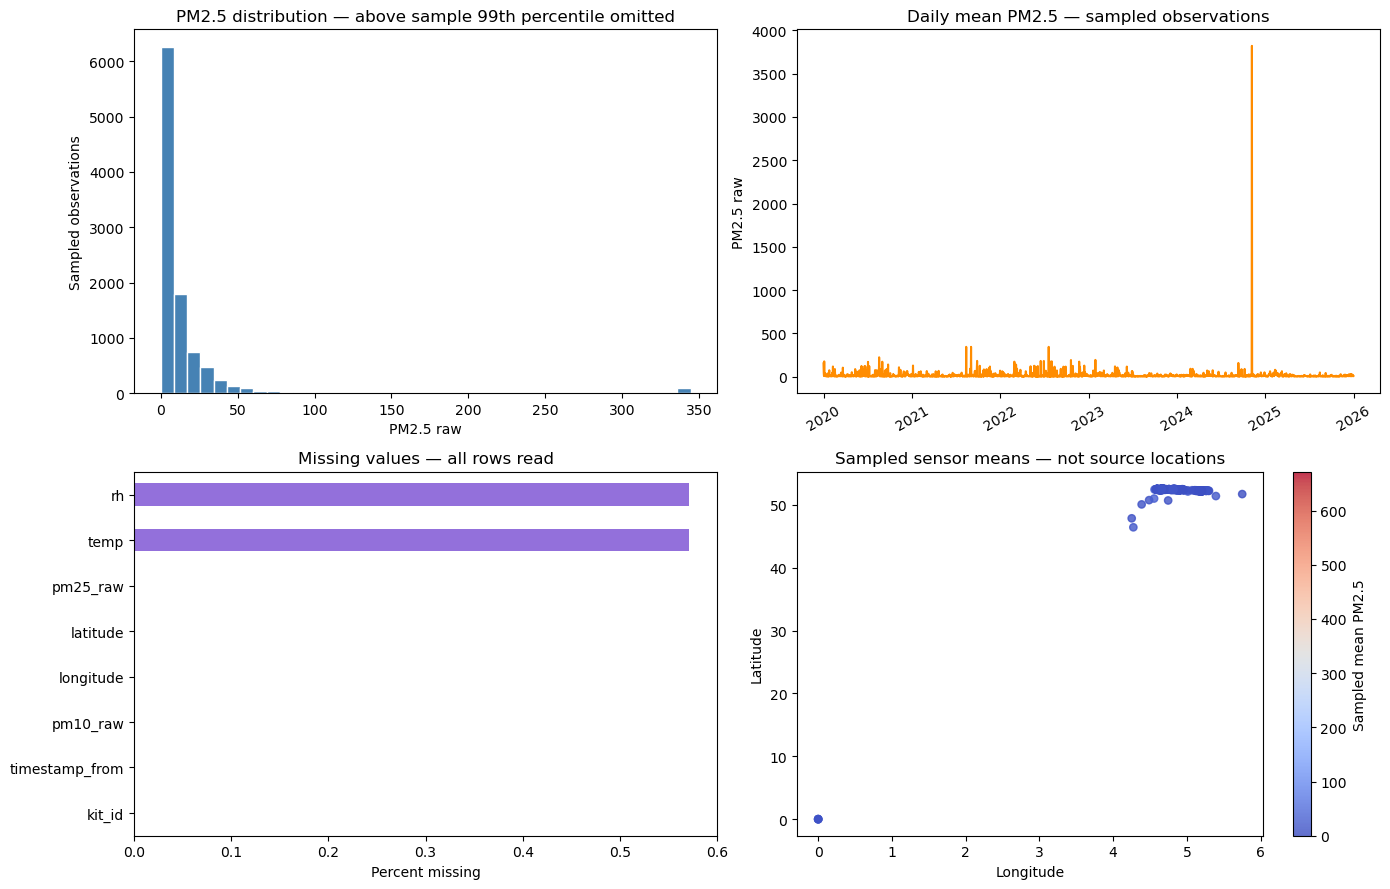

In [1]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

# Change this path to analyse a different sensor Parquet file.
FILE = "../data/data_sensors.parquet"  # relative to notebooks/
BATCH_SIZE = 100_000
SAMPLE_SIZE = 10_000

parquet = pq.ParquetFile(FILE)
print("File:", FILE)
print("Total rows in metadata:", f"{parquet.metadata.num_rows:,}")
print("Row groups:", parquet.metadata.num_row_groups)
print("\nSchema:\n", parquet.schema_arrow.remove_metadata())

# Only read the columns needed below, when they exist.
wanted = ["kit_id", "timestamp_from", "pm25_raw", "pm10_raw", "temp", "rh", "latitude", "longitude"]
columns = [c for c in wanted if c in parquet.schema_arrow.names]
required = ["kit_id", "timestamp_from", "pm25_raw"]
missing = [c for c in required if c not in columns]
if missing:
    raise ValueError(f"Required columns not found: {missing}")
print("\nColumns used:", columns)
print("Reading the full file in batches; this may take a while...\n")

rng = np.random.default_rng(42)
sample = pd.DataFrame()
null_counts = pd.Series(0, index=columns, dtype="int64")
rows_read = 0

for batch_number, batch in enumerate(parquet.iter_batches(batch_size=BATCH_SIZE, columns=columns), 1):
    chunk = batch.to_pandas()
    rows_read += len(chunk)
    null_counts += chunk.isna().sum()

    # Random priorities give a uniform sample of rows across all batches read.
    chunk["_sample_key"] = rng.random(len(chunk))
    sample = pd.concat([sample, chunk], ignore_index=True).nsmallest(SAMPLE_SIZE, "_sample_key")
    if batch_number % 10 == 0:
        print(f"Read {rows_read:,} rows...")

if sample.empty:
    raise ValueError("The file contains no readable rows.")
sample = sample.drop(columns="_sample_key").copy()
sample["time_utc"] = pd.to_datetime(sample["timestamp_from"], errors="coerce", utc=True)
for col in ["pm25_raw", "pm10_raw", "temp", "rh", "latitude", "longitude"]:
    if col in sample.columns:
        sample[col] = pd.to_numeric(sample[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

print("\nRows read:", f"{rows_read:,}")
print("Sample size:", f"{len(sample):,}")
print("Sensors represented in sample:", sample["kit_id"].nunique())
print("Sampled time range (UTC):", sample["time_utc"].min(), "to", sample["time_utc"].max())
print("\nMissing values in selected columns — exact for all rows read:")
print(pd.DataFrame({"missing": null_counts, "percent": 100 * null_counts / rows_read}).round(2).to_string())
print("\nPM2.5 summary — estimates from the random sample:")
print(sample["pm25_raw"].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).to_string())
print("Negative PM2.5 values in sample:", int((sample["pm25_raw"] < 0).sum()))

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
pm = sample["pm25_raw"].dropna()
if not pm.empty:
    cutoff = pm.quantile(0.99)
    ax[0, 0].hist(pm[pm <= cutoff], bins=40, color="steelblue", edgecolor="white")
    ax[0, 0].set_title("PM2.5 distribution — above sample 99th percentile omitted")
    ax[0, 0].set_xlabel("PM2.5 raw")
    ax[0, 0].set_ylabel("Sampled observations")

by_day = sample.dropna(subset=["time_utc", "pm25_raw"]).copy()
if not by_day.empty:
    daily = by_day.groupby(by_day["time_utc"].dt.floor("D"))["pm25_raw"].mean()
    ax[0, 1].plot(daily.index, daily.values, color="darkorange")
    ax[0, 1].set_title("Daily mean PM2.5 — sampled observations")
    ax[0, 1].set_ylabel("PM2.5 raw")
    ax[0, 1].tick_params(axis="x", rotation=30)

(100 * null_counts / rows_read).sort_values().plot.barh(ax=ax[1, 0], color="mediumpurple")
ax[1, 0].set_title("Missing values — all rows read")
ax[1, 0].set_xlabel("Percent missing")

if {"latitude", "longitude"}.issubset(sample.columns):
    geo = sample.dropna(subset=["kit_id", "latitude", "longitude", "pm25_raw"])
    if not geo.empty:
        sensors = geo.groupby("kit_id").agg(lat=("latitude", "mean"), lon=("longitude", "mean"),
                                               pm=("pm25_raw", "mean"), n=("pm25_raw", "size"))
        scatter = ax[1, 1].scatter(sensors["lon"], sensors["lat"], c=sensors["pm"],
                                   cmap="coolwarm", s=28, alpha=0.8)
        fig.colorbar(scatter, ax=ax[1, 1], label="Sampled mean PM2.5")
        ax[1, 1].set_xlabel("Longitude")
        ax[1, 1].set_ylabel("Latitude")
ax[1, 1].set_title("Sampled sensor means — not source locations")

plt.tight_layout()
plt.show()
